### Week 11 notebook - Clustering Part 2: DBSCAN, Hierarchical Agglomerative Clustering (HAC), Linkage Methods and Dendrograms, Mod C Data Science Capstone Fall 2026
### By Shuqin Ouyang

# Overall notebook structure:

Breadth week, so only the two topics from the reading, each run on both datasets:
1. DBSCAN (eps, MinPts, and core, border and noise points), with the failure rate of the noise rows and which features set them apart
2. Hierarchical agglomerative clustering (HAC): four linkage methods and a dendrogram
3. Conclusion and Summary

The setup is the same as Week 10: the Weeks 5 to 9 80/20 split and scaled training rows (the scaler is fit on the training rows only). DBSCAN uses all the training rows. HAC compares every row with every other row, which is too big for all rows, so it uses a random 2,000-row sample of them. The failure label is never used to build the clusters.

# Student dataset analysis starts here:

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from scipy.cluster.hierarchy import linkage, dendrogram

In [2]:
MIN_PTS = 10    # DBSCAN MinPts: rows needed within eps (counting the row itself) to be a core point. A common default, not tuned

Helper functions (used for both datasets):

In [3]:
def dbscan_table(Z, y):
    # DBSCAN at three eps values: the 50th, 75th and 90th percentile of each row's distance to its MIN_PTS-th nearest row.
    # Also the failure rate of the noise rows against the rows in clusters (the label is only used here, after clustering)
    dist = NearestNeighbors(n_neighbors=MIN_PTS).fit(Z).kneighbors(Z)[0][:, -1]
    rows = []
    for p in [50, 75, 90]:
        eps = np.percentile(dist, p)
        labels = DBSCAN(eps=eps, min_samples=MIN_PTS).fit_predict(Z)
        noise = labels == -1
        rows.append({'percentile': p, 'eps': eps, 'clusters': labels.max() + 1, 'noise rows': noise.sum(), 'noise share': noise.mean(),
                     'failure rate (noise)': y[noise].mean(), 'failure rate (in clusters)': y[~noise].mean()})
    return pd.DataFrame(rows).set_index('percentile')

def hac_sizes(Z):
    # rows in each cluster when HAC is cut at 3 clusters, for each linkage method
    sizes = {}
    for method in ['single', 'complete', 'average', 'ward']:
        labels = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(Z)
        sizes[method] = pd.Series(labels).value_counts().tolist()
    return pd.Series(sizes, name='rows in each cluster')

Dataset 1 background quick overview:

The dataset 1 used is the Taiwanese Bankruptcy Prediction dataset from UCI, link as https://archive.ics.uci.edu/dataset/572/taiwanese+bankruptcy+prediction.
It contains company financial indicators and a binary outcome for bankruptcy.

In [4]:
# install uci package so can load the data using package
# install once in terminal or notebook

!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# load dataset from UCI repository using dataset id
data_bankruptcy = fetch_ucirepo(id=572)

df_bankruptcy = pd.concat(
    [data_bankruptcy.data.features.copy(),
     data_bankruptcy.data.targets.copy()],
    axis=1
)

# remove leading/trailing spaces from column names once, here
df_bankruptcy.columns = df_bankruptcy.columns.str.strip()

df_bankruptcy.head()

'pip' is not recognized as an internal or external command,
operable program or batch file.


,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),...,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability,Bankrupt?
0,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,0.780985,...,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469,1
1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,0.781506,...,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794,1
2,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,0.780284,...,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474,1
3,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,0.781241,...,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982,1
4,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,0.781550,...,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490,1


Student markdown:

Dataset 1 is the Taiwanese bankruptcy data: 6,819 companies described by 95 financial ratios, of which about 3.2% went bankrupt. All features are numeric and none are missing.

In [5]:
X_train_bankrupt, X_test_bankrupt, y_train_bankrupt, y_test_bankrupt = train_test_split(df_bankruptcy.drop(columns='Bankrupt?'), df_bankruptcy['Bankrupt?'], test_size=0.2, stratify=df_bankruptcy['Bankrupt?'], random_state=42)    # same split as Weeks 5, 6, 8 and 9
scaler_bankrupt = StandardScaler().fit(X_train_bankrupt)
Z_bankrupt = scaler_bankrupt.transform(X_train_bankrupt)    # scaled training rows. K-Means never sees the target

Topic 1: DBSCAN on the scaled training rows. DBSCAN has two settings. eps is the neighborhood radius, and MinPts (here 10) is how many rows, counting the row itself, must be within eps for a row to be a core point. Core points with enough neighbors form the dense regions, border points are within eps of a core point but have too few neighbors themselves, and noise points belong to no cluster. There is no k to choose, but eps decides the result: too small labels many rows as noise, and too large merges everything into one cluster. To choose eps without guessing, I take each row's distance to its 10th nearest row and try eps at the 50th, 75th and 90th percentile of those distances. The table shows the number of clusters and the noise rows for each, and the failure rate of the noise rows against the rows in clusters. DBSCAN's noise rows are the outliers, so the question is whether they fail more often. The label is only used for this, after clustering.

In [6]:
print("overall failure rate (train):", round(y_train_bankrupt.mean(), 3))
table_db_bankrupt = dbscan_table(Z_bankrupt, y_train_bankrupt)
print(table_db_bankrupt.round(3).to_string())

overall failure rate (train): 0.032
              eps  clusters  noise rows  noise share  failure rate (noise)  failure rate (in clusters)
percentile                                                                                            
50          3.822         1        1785        0.327                 0.062                       0.018
75          4.818         1         853        0.156                 0.073                       0.025
90          6.678         3         325        0.060                 0.126                       0.026


Student markdown:

For bankruptcy, DBSCAN finds one cluster at the 50th and 75th percentile eps (3.822 and 4.818), and three clusters only at the 90th (6.678). The noise share falls from 0.327 to 0.060 as eps grows, as expected for a larger radius. The useful result is the failure rate. The noise rows fail more often than the rows in clusters at every eps (0.062, 0.073 and 0.126 against 0.018, 0.025 and 0.026), and at the 90th percentile the 325 noise rows fail at 0.126, about 4 times the overall rate of 0.032. So the outliers that DBSCAN sets aside are a risk signal for bankruptcy, which fits the extreme companies seen in Week 10. DBSCAN cannot assign new rows, so this is on the training rows only.

Which features set the bankruptcy noise rows apart? At the 90th-percentile eps, the average scaled value of each feature is compared between the noise rows and the rows in clusters. The five largest gaps are shown, in standard deviations (a positive gap means the feature is higher in the noise rows).

In [7]:
noise_bankrupt = DBSCAN(eps=table_db_bankrupt.loc[90, 'eps'], min_samples=MIN_PTS).fit_predict(Z_bankrupt) == -1    # noise rows at the 90th percentile eps
Z_df_bankrupt = pd.DataFrame(Z_bankrupt, columns=X_train_bankrupt.columns)
gap_bankrupt = Z_df_bankrupt[noise_bankrupt].mean() - Z_df_bankrupt[~noise_bankrupt].mean()    # average scaled value: noise rows minus clustered rows
print(gap_bankrupt.sort_values(key=abs, ascending=False).head(5).round(2))

Retained Earnings to Total Assets      -0.96
Inventory/Current Liability             0.93
Net Income to Total Assets             -0.83
Total assets to GNP price               0.83
Long-term fund suitability ratio (A)    0.75
dtype: float64


Student markdown:

The noise rows differ from the clustered rows by less than 1 standard deviation on every feature, so no single feature makes a row an outlier. The largest gaps are lower Retained Earnings to Total Assets (-0.96) and lower Net Income to Total Assets (-0.83), and higher Inventory/Current Liability (0.93), Total assets to GNP price (0.83) and Long-term fund suitability ratio (A) (0.75). The two lower ones are profitability measures, so weak profitability is a plausible reason why these rows fail more often (my reading, not tested). These are averages over 325 noise rows that fail at 0.126, so most of them did not fail, and I did not compare these features with the important features from the supervised weeks.

Topic 2: hierarchical agglomerative clustering (HAC) on a random 2,000-row sample of the scaled training rows. HAC starts with every row as its own cluster and keeps merging the two closest clusters. The linkage method decides how the distance between two clusters is measured: single (the closest pair of rows), complete (the farthest pair), average (the mean of all pairs) and Ward (the merge that raises the squared error the least). The table cuts the tree at 3 clusters for each linkage and shows the cluster sizes. The dendrogram shows the Ward merges: the height is the distance at which two clusters were merged, and cutting the tree at a height gives the clusters below it (the x-axis shows the last 15 clusters, with the number of rows in brackets).

In [8]:
Z_sample_bankrupt = pd.DataFrame(Z_bankrupt).sample(2000, random_state=42)    # random 2,000 scaled training rows
print(hac_sizes(Z_sample_bankrupt))

single      [1998, 1, 1]
complete    [1998, 1, 1]
average     [1998, 1, 1]
ward        [1998, 1, 1]
Name: rows in each cluster, dtype: object


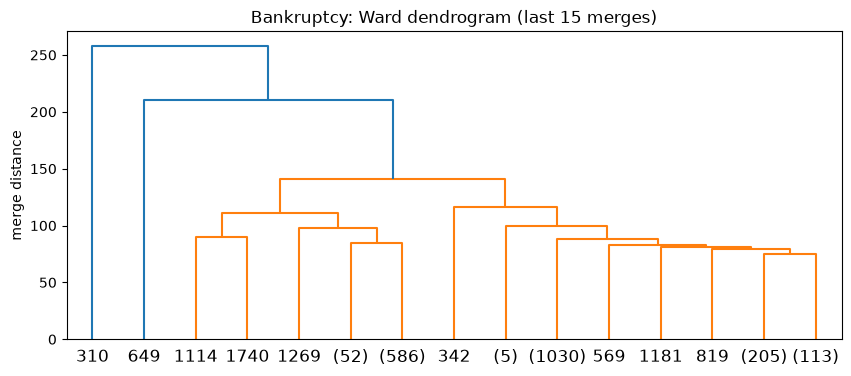

In [9]:
plt.figure(figsize=(10, 4))
dendrogram(linkage(Z_sample_bankrupt, method='ward'), truncate_mode='lastp', p=15)
plt.title('Bankruptcy: Ward dendrogram (last 15 merges)')
plt.ylabel('merge distance')
plt.show()

Student markdown:

All four linkages give the same cut at 3 clusters: 1,998 rows and two single-row clusters. So even Ward, which usually gives balanced clusters, is dominated by two extreme companies, and the linkage choice makes no difference here. The Ward dendrogram shows the same thing: two single rows join the rest at much larger heights (about 260 and 210) than the next merge (about 140), and the remaining merges fall gradually with no obvious gap. These two rows are probably the same kind of extreme companies as the two single-company clusters in Week 10, but I did not check that they are the same rows.

Dataset 2 background quick overview:

The dataset 2 used is the Default of Credit Card Clients dataset from UCI, link as https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients.

It contains demographic information, credit limits, repayment history, bill statements, and previous payment records for Taiwanese credit card clients, along with a binary outcome indicating whether the client defaulted on the next payment.

In [10]:
# UCI dataset already decides features and targets already, but still need to look into details / verify to make sure all ok
data_credit = fetch_ucirepo(id=350)

df_credit = pd.concat(
    [data_credit.data.features.copy(),
     data_credit.data.targets.copy()],
    axis=1
)

df_credit.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [11]:
# columns rename for easier reading

df_credit = df_credit.rename(columns={

    "Y": "default_next_month",

    "X1": "credit_limit",
    "X2": "gender",
    "X3": "education",
    "X4": "marital_status",
    "X5": "age",

    "X6": "repay_2005_sep",
    "X7": "repay_2005_aug",
    "X8": "repay_2005_jul",
    "X9": "repay_2005_jun",
    "X10": "repay_2005_may",
    "X11": "repay_2005_apr",

    "X12": "bill_2005_sep",
    "X13": "bill_2005_aug",
    "X14": "bill_2005_jul",
    "X15": "bill_2005_jun",
    "X16": "bill_2005_may",
    "X17": "bill_2005_apr",

    "X18": "pay_2005_sep",
    "X19": "pay_2005_aug",
    "X20": "pay_2005_jul",
    "X21": "pay_2005_jun",
    "X22": "pay_2005_may",
    "X23": "pay_2005_apr"
})

df_credit.head()

,credit_limit,gender,education,marital_status,age,repay_2005_sep,repay_2005_aug,repay_2005_jul,repay_2005_jun,repay_2005_may,...,bill_2005_jun,bill_2005_may,bill_2005_apr,pay_2005_sep,pay_2005_aug,pay_2005_jul,pay_2005_jun,pay_2005_may,pay_2005_apr,default_next_month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Student markdown:

Dataset 2 is the credit card default data: 30,000 clients described by 23 features (credit limit, demographics, six months of repayment status, bill amounts and payments), of which about 22% default next month. No values are missing.

In [12]:
X_train_credit, X_test_credit, y_train_credit, y_test_credit = train_test_split(df_credit.drop(columns='default_next_month'), df_credit['default_next_month'], test_size=0.2, stratify=df_credit['default_next_month'], random_state=42)    # same split as Weeks 5, 6, 8 and 9
scaler_credit = StandardScaler().fit(X_train_credit)
Z_credit = scaler_credit.transform(X_train_credit)    # scaled training rows. K-Means never sees the target

Topic 1 for credit card: the same DBSCAN and the same three eps values as for bankruptcy.

In [13]:
print("overall failure rate (train):", round(y_train_credit.mean(), 3))
table_db_credit = dbscan_table(Z_credit, y_train_credit)
print(table_db_credit.round(3).to_string())

overall failure rate (train): 0.221
              eps  clusters  noise rows  noise share  failure rate (noise)  failure rate (in clusters)
percentile                                                                                            
50          1.369        57        9030        0.376                 0.262                       0.197
75          2.014         2        3803        0.158                 0.226                       0.220
90          2.804         4        1492        0.062                 0.158                       0.225


Student markdown:

For credit card, DBSCAN is much more sensitive to eps. It finds 57 clusters at the 50th percentile (eps 1.369), 2 at the 75th (2.014) and 4 at the 90th (2.804), and the noise share falls from 0.376 to 0.062. The failure rate of the noise rows does not hold up. They fail more than the rows in clusters only at the smallest eps (0.262 against 0.197), about the same at the 75th (0.226 against 0.220), and less at the 90th (0.158 against 0.225), with an overall rate of 0.221. So for credit card the outliers are not a risk signal, and the clusters change a lot with eps, so there is no stable result. This is also on the training rows only.

Which features set the credit card noise rows apart? The same comparison as for bankruptcy, at the 90th-percentile eps.

In [14]:
noise_credit = DBSCAN(eps=table_db_credit.loc[90, 'eps'], min_samples=MIN_PTS).fit_predict(Z_credit) == -1    # noise rows at the 90th percentile eps
Z_df_credit = pd.DataFrame(Z_credit, columns=X_train_credit.columns)
gap_credit = Z_df_credit[noise_credit].mean() - Z_df_credit[~noise_credit].mean()    # average scaled value: noise rows minus clustered rows
print(gap_credit.sort_values(key=abs, ascending=False).head(5).round(2))

pay_2005_may    1.64
pay_2005_apr    1.64
pay_2005_jun    1.59
pay_2005_sep    1.48
pay_2005_aug    1.46
dtype: float64


Student markdown:

The credit card noise rows differ from the clustered rows by much more than the bankruptcy ones did. The five largest gaps are all payment amount columns and all are 1.46 to 1.64 standard deviations higher (pay_2005_may 1.64, pay_2005_apr 1.64, pay_2005_jun 1.59, pay_2005_sep 1.48 and pay_2005_aug 1.46). So the DBSCAN outliers for credit card are clients who paid unusually large amounts, and a few related features set them apart, unlike bankruptcy, where the gaps were smaller and spread over different features. These noise rows fail less often than the clustered rows (0.158 against 0.225), which fits large payers being less likely to default (my reading, not tested). These are payment amount columns, not the repayment status columns, and I did not compare them with the important features from the supervised weeks.

Topic 2 for credit card: the same sample size, linkage sizes and Ward dendrogram as for bankruptcy.

In [15]:
Z_sample_credit = pd.DataFrame(Z_credit).sample(2000, random_state=42)    # random 2,000 scaled training rows
print(hac_sizes(Z_sample_credit))

single          [1998, 1, 1]
complete       [1986, 13, 1]
average         [1997, 2, 1]
ward        [1115, 688, 197]
Name: rows in each cluster, dtype: object


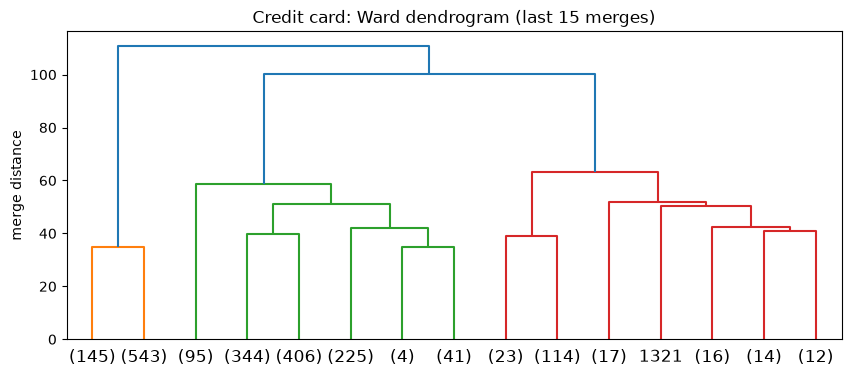

In [16]:
plt.figure(figsize=(10, 4))
dendrogram(linkage(Z_sample_credit, method='ward'), truncate_mode='lastp', p=15)
plt.title('Credit card: Ward dendrogram (last 15 merges)')
plt.ylabel('merge distance')
plt.show()

Student markdown:

The linkages give different cuts for credit card. Single, complete and average linkage put almost all rows in one cluster (1,998, 1,986 and 1,997 rows, with 1 to 13 rows in the others), while Ward gives three sizeable clusters (1,115, 688 and 197 rows). This is the pattern from the reading: single linkage joins nearby rows one by one into a chain, while Ward merges so that the squared error grows the least, which gives rounder and more balanced groups. In the Ward dendrogram, the 1,115-row and 197-row groups join at about 100 and the 688-row group joins them last at about 110, so the three-way cut is reasonable but not sharp. Unlike bankruptcy, the linkage choice matters here.

Student markdown:

Conclusion:

**Overfitting:** I did not test overfitting, because clustering has no train/test score, and DBSCAN cannot assign unseen rows, so every check this week uses training rows only. I did not tune anything toward the failure label: eps comes from percentiles of the distances, MinPts is a fixed 10, and the label is used only afterwards. The checks I ran measure stability across settings, not overfitting. The bankruptcy noise-failure gap holds at all three eps values, while the credit card gap changes with eps, and the HAC cut for bankruptcy is the same under all four linkages, while for credit card it depends on the linkage.

**Metrics and results:** there is no F1 or silhouette this week. I judge the results mainly by the number of clusters, the failure rate (of the noise rows against the rows in clusters for DBSCAN) and the charts, meaning the Ward dendrograms and the cluster sizes at 3 clusters for HAC. For bankruptcy, the noise rows fail much more than the clustered rows (0.126 against 0.026 at the 90th percentile eps), and HAC always isolates two single rows. For credit card, the noise rows are not riskier (0.158 against 0.225 at the 90th percentile), and only Ward gives balanced clusters (1,115, 688 and 197 rows).

**Expected vs. unexpected:**
- Expected: bankruptcy to have fewer clusters than credit card, and the outlier-group situation from the Week 10 clustering to show up again, with extreme companies standing apart and failing more often. Both held: bankruptcy had 1, 1 and 3 DBSCAN clusters against 57, 2 and 4 for credit card, and its noise rows fail much more often (0.126 against 0.026 at the 90th percentile eps).
- Unexpected, bankruptcy: the four linkage methods gave the same clusters (1,998 rows plus two single rows).
- Unexpected, credit card: the linkage methods gave different results (single, complete and average linkage chain, while Ward gives 1,115, 688 and 197 rows), and the DBSCAN clusters changed a lot as eps increased (57, 2 and 4 clusters). The noise rows also failed less (0.158) than the clustered rows at the largest eps.

**EDA usefulness:** the Week 10 findings and the EDA helped this week, because I knew what to expect. The outliers seen earlier helped me expect what would happen: outlier-driven clusters and risky noise rows for bankruptcy. I did not check that the two single-row HAC clusters are the same rows as in Week 10. The EDA did not tell which eps or linkage would work, and it did not predict the unstable credit card results.

**Bigger picture, research questions:**
- RQ1, which risk signals keep appearing: for bankruptcy, being an outlier keeps appearing. The DBSCAN noise rows fail about 4 times the overall rate at the 90th percentile, and this fits the risky cluster and extreme companies of Week 10. The noise rows differ most by weaker profitability (lower Retained Earnings to Total Assets and Net Income to Total Assets) and higher Inventory/Current Liability, but no feature differs by a full standard deviation. For credit card, outliers are not a risk signal: the noise rows are clients with unusually large payment amounts (the five largest gaps are all payment columns, 1.46 to 1.64 standard deviations higher) and they fail less, so its risk stays with the repayment signal found by the supervised models in Weeks 6, 8 and 9.
- RQ2, whether bankruptcy is harder to model: the answer is mixed, as in Week 10. Bankruptcy structure is dominated by a few extreme rows (two single rows under every linkage, one DBSCAN cluster at two of three eps), which makes it harder to cluster cleanly. But those extreme rows carry the failure signal, so they are useful, not only a problem.
- RQ3, whether results stay stable across settings: for bankruptcy, the noise-failure gap holds across all three eps values and the HAC cut holds across all four linkages. For credit card, the DBSCAN clusters change a lot with eps (57, 2 and 4), the noise-failure gap changes with eps, and the HAC cut depends on the linkage. So with these methods, credit card is the less stable dataset, unlike with K-Means in Week 10.

**How I know the conclusions are true:** all results use training rows only, with one split, one random sample and one MinPts. The 90th percentile bankruptcy result rests on 325 noise rows, and the HAC result for bankruptcy rests on two single rows, so both are indicative only. HAC used a 2,000-row sample, not all rows. The feature gaps are averages over the noise rows, so they show what is typical, not what causes a failure. The three eps values are percentiles of the distances, so the noise share is set by the choice of percentile and is not a finding by itself.

Summary:

| | Dataset 1: Bankruptcy | Dataset 2: Credit card |
|---|---|---|
| Overall failure rate (training) | 0.032 | 0.221 |
| DBSCAN clusters at the 50th / 75th / 90th percentile eps | 1 / 1 / 3 | 57 / 2 / 4 |
| Failure rate, noise rows vs clustered rows (90th percentile eps) | 0.126 vs 0.026 | 0.158 vs 0.225 |
| HAC cluster sizes at 3 clusters, Ward | 1,998 / 1 / 1 | 1,115 / 688 / 197 |
| Linkage choice matters | no | yes |
| Largest feature gap, noise rows vs clustered rows (standard deviations) | Retained Earnings to Total Assets (-0.96) | pay_2005_may (1.64) |

For bankruptcy, DBSCAN's outliers are a stable risk signal, and the HAC result is dominated by two extreme companies under every linkage. For credit card, the outliers are clients with unusually large payments and are not risky, DBSCAN changes a lot with eps, and only Ward gives balanced clusters. The main limits are that everything uses training rows only, HAC uses a 2,000-row sample, and the bankruptcy results rest on a few hundred noise rows and two single rows.